# Can Saliency Maps Flag Chest Radiograph Classifier Errors at a New Hospital? An External Validation Study
## CNN Training
## Aashish Chapagai (Last Edited: September 2026)

In [1]:
import os

os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import json
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, auc
from sklearn.metrics import classification_report, multilabel_confusion_matrix
from sklearn.model_selection import GroupShuffleSplit

tf.get_logger().setLevel('ERROR')

os.makedirs('models', exist_ok=True)
os.makedirs('figures', exist_ok=True)

In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
    print(f"Training on {gpus[0].name} with mixed float16 precision.")

Training on /physical_device:GPU:0 with mixed float16 precision.


In [3]:
X_train = np.load('models/X_train.npy', mmap_mode='r')
X_test = np.load('models/X_test.npy', mmap_mode='r')
Y_train = np.load('models/Y_train.npy')
Y_test = np.load('models/Y_test.npy')
disease_classes = np.load('models/disease_classes.npy').tolist()
train_patient_ids = np.load('models/train_patient_ids.npy', allow_pickle=True)
test_patient_ids = np.load('models/test_patient_ids.npy', allow_pickle=True)

IMG_SIZE = X_train.shape[1]
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
EPOCHS = 12
SEED = 42
VAL_FRACTION = 0.15
WARMUP_EPOCHS = 2
POS_WEIGHT_CAP = 8.0
HEAD_LR = 1e-3
WEIGHT_DECAY = 0.05
EMA_MOMENTUM = 0.999
DROPOUT = 0.5
BACKBONE_LR = float(1e-4 * np.sqrt(BATCH_SIZE / 32))
N_BOOTSTRAP = 1000
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_VARIANCE = [0.229 ** 2, 0.224 ** 2, 0.225 ** 2]
tf.keras.utils.set_random_seed(SEED)

print(f"Loaded {X_train.shape[0]} training and {X_test.shape[0]} test images at {IMG_SIZE}px ({X_train.dtype}).")
print(f"Predicting {len(disease_classes)} disease classes.")

shared_patients = set(train_patient_ids).intersection(test_patient_ids)
print(f"Patients appearing in both train and test: {len(shared_patients)}")

Loaded 90286 training and 21834 test images at 320px (uint8).
Predicting 14 disease classes.
Patients appearing in both train and test: 0


In [4]:
gss_val = GroupShuffleSplit(n_splits=1, test_size=VAL_FRACTION, random_state=SEED)
tr_sub_idx, val_sub_idx = next(gss_val.split(np.zeros(len(Y_train)), Y_train, groups=train_patient_ids))

tr_sub_idx = np.sort(tr_sub_idx)
val_sub_idx = np.sort(val_sub_idx)
Y_tr, Y_val = Y_train[tr_sub_idx], Y_train[val_sub_idx]
print(f"Training on {len(tr_sub_idx)} images, validating on {len(val_sub_idx)}.")

Training on 76491 images, validating on 13795.


In [5]:
pos_counts = Y_tr.sum(axis=0).astype(np.float32)
pos_weight = np.clip((len(Y_tr) - pos_counts) / np.maximum(pos_counts, 1.0), 1.0, POS_WEIGHT_CAP)
print("Positive class weights:")
for name, weight in zip(disease_classes, pos_weight):
    print(f"  {name:<20}{weight:>6.1f}")

def make_weighted_bce(weights):
    def weighted_bce(y_true, logits):
        labels = tf.cast(y_true, tf.float32)
        per_class = tf.nn.weighted_cross_entropy_with_logits(labels, tf.cast(logits, tf.float32), weights)
        return tf.reduce_mean(tf.reduce_sum(per_class, axis=-1))
    return weighted_bce
    
loss_function = make_weighted_bce(tf.constant(pos_weight, dtype=tf.float32))

Positive class weights:
  Atelectasis            8.0
  Cardiomegaly           8.0
  Consolidation          8.0
  Edema                  8.0
  Effusion               7.4
  Emphysema              8.0
  Fibrosis               8.0
  Hernia                 8.0
  Infiltration           4.7
  Mass                   8.0
  Nodule                 8.0
  Pleural_Thickening     8.0
  Pneumonia              8.0
  Pneumothorax           8.0


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

brightness = tf.keras.layers.RandomBrightness(0.15, value_range=(0.0, 255.0), dtype='float32')
contrast = tf.keras.layers.RandomContrast(0.15, dtype='float32')
rotation = tf.keras.layers.RandomRotation(0.04, fill_mode='nearest', dtype='float32')
zoom = tf.keras.layers.RandomZoom((-0.10, 0.10), fill_mode='nearest', dtype='float32')
translation = tf.keras.layers.RandomTranslation(0.07, 0.07, fill_mode='nearest', dtype='float32')

def augment(images, labels):
    x = tf.image.random_flip_left_right(tf.cast(images, tf.float32))
    x = contrast(brightness(x, training=True), training=True)
    x = tf.clip_by_value(x, 0.0, 255.0)
    x = translation(zoom(rotation(x, training=True), training=True), training=True)
    return x, labels
    
def make_dataset(source, indices, labels, batch_size, training):
    labels = np.ascontiguousarray(labels, dtype=np.float32)
    batch_dim = batch_size if training else None

    def read(batch):
        return np.asarray(source[batch]), labels[batch]

    def fetch(batch):
        images, targets = tf.numpy_function(read, [batch], [tf.uint8, tf.float32])
        images.set_shape([batch_dim, IMG_SIZE, IMG_SIZE, 1])
        targets.set_shape([batch_dim, labels.shape[1]])
        return images, targets

    ds = tf.data.Dataset.from_tensor_slices(indices.astype(np.int64))
    if training:
        ds = ds.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size, drop_remainder=training)
    ds = ds.map(fetch, num_parallel_calls=AUTOTUNE, deterministic=not training)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE, deterministic=False)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, tr_sub_idx, Y_train, BATCH_SIZE, training=True)
val_ds = make_dataset(X_train, val_sub_idx, Y_train, EVAL_BATCH_SIZE, training=False)

In [7]:
def build_densenet(n_classes, img_size, dropout):
    shape = (img_size, img_size, 3)
    base = tf.keras.applications.DenseNet121(include_top=False, weights='imagenet', input_shape=shape, name='densenet121_base')

    inputs = tf.keras.Input(shape=(img_size, img_size, 1), dtype='float32', name='image')
    x = tf.keras.layers.Rescaling(1.0 / 255.0, name='rescale')(inputs)
    x = tf.keras.layers.Concatenate(name='to_rgb')([x, x, x])
    x = tf.keras.layers.Normalization(mean=IMAGENET_MEAN, variance=IMAGENET_VARIANCE, name='imagenet_norm')(x)
    x = base(x)
    x = tf.keras.layers.GlobalAveragePooling2D(name='gap')(x)
    x = tf.keras.layers.Dropout(dropout, name='head_dropout')(x)
    logits = tf.keras.layers.Dense(n_classes, dtype='float32', name='logits')(x)
    probabilities = tf.keras.layers.Activation('sigmoid', dtype='float32', name='predictions')(logits)
    model = tf.keras.Model(inputs, probabilities, name='densenet121_cxr')
    trainer = tf.keras.Model(inputs, logits, name='densenet121_cxr_logits')
    return model, trainer, base

cnn, trainer, base_model = build_densenet(len(disease_classes), IMG_SIZE, DROPOUT)
cnn.summary()

def auc_metric():
    return tf.keras.metrics.AUC(multi_label=True, num_labels=len(disease_classes), from_logits=True, name='auc')

Model: "densenet121_cxr"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 320, 320,  │          0 │ -                 │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cast_1 (Cast)       │ (None, 320, 320,  │          0 │ image[0][0]       │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescale (Rescaling) │ (None, 320, 320,  │          0 │ cast_1[0][0]      │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ to_rgb              │ (None, 320, 320,  │          0 │ rescale[0][0],    │
│ (Concatenate)       │ 3)                │            │ rescale[0][0],    │
│                     │                   │            │ rescale[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ imagenet_norm       │ (None, 320, 320,  │          0 │ to_rgb[0][0]      │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ densenet121_base    │ (None, 10, 10,    │  7,037,504 │ imagenet_norm[0]… │
│ (Functional)        │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gap                 │ (None, 1024)      │          0 │ densenet121_base… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dropout        │ (None, 1024)      │          0 │ gap[0][0]         │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cast_2 (Cast)       │ (None, 1024)      │          0 │ head_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits (Dense)      │ (None, 14)        │     14,350 │ cast_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predictions         │ (None, 14)        │          0 │ logits[0][0]      │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,051,854 (26.90 MB)

 Trainable params: 6,968,206 (26.58 MB)

 Non-trainable params: 83,648 (326.75 KB)

In [8]:
print("\nPhase 1: Training classification head")
base_model.trainable = False
head_optimizer = tf.keras.optimizers.Adam(HEAD_LR)
trainer.compile(optimizer=head_optimizer, loss=loss_function, metrics=[auc_metric()], jit_compile=True)
trainer.fit(train_ds, validation_data=val_ds, epochs=WARMUP_EPOCHS, verbose=1)


Phase 1: Training classification head
Epoch 1/2
2390/2390 ━━━━━━━━━━━━━━━━━━━━ 182s 63ms/step - auc: 0.5799 - loss: 10.2560 - val_auc: 0.7253 - val_loss: 8.8364
Epoch 2/2
2390/2390 ━━━━━━━━━━━━━━━━━━━━ 110s 46ms/step - auc: 0.6614 - loss: 9.3253 - val_auc: 0.7371 - val_loss: 8.9472


In [9]:
print("\nPhase 2: Full fine-tuning")
base_model.trainable = True

steps_per_epoch = len(tr_sub_idx) // BATCH_SIZE
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=BACKBONE_LR / 100,
    warmup_target=BACKBONE_LR,
    warmup_steps=steps_per_epoch,
    decay_steps=steps_per_epoch * (EPOCHS - 1),
    alpha=0.02
)

optimizer = tf.keras.optimizers.AdamW(lr_schedule, weight_decay=WEIGHT_DECAY, use_ema=True, ema_momentum=EMA_MOMENTUM)
optimizer.exclude_from_weight_decay(var_names=['bias', 'gamma', 'beta'])

trainer.compile(optimizer=optimizer, loss=loss_function, metrics=[auc_metric()], jit_compile=True)

best_weights = 'models/best.weights.h5'
final_weights = 'models/final.weights.h5'

backup = tf.keras.callbacks.BackupAndRestore('models/backup')
checkpoint = tf.keras.callbacks.ModelCheckpoint(best_weights, monitor='val_auc', mode='max', save_best_only=True, save_weights_only=True, verbose=1)
history = trainer.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1, callbacks=[backup, checkpoint])
np.save('models/history.npy', history.history, allow_pickle=True)

ema_optimizer = getattr(trainer.optimizer, 'inner_optimizer', trainer.optimizer)
ema_optimizer.finalize_variable_values(trainer.trainable_variables)
trainer.save_weights(final_weights)
final_auc = trainer.evaluate(val_ds, verbose=0, return_dict=True)['auc']

trainer.load_weights(best_weights)
best_auc = trainer.evaluate(val_ds, verbose=0, return_dict=True)['auc']

if final_auc >= best_auc:
    trainer.load_weights(final_weights)
    print(f"Keeping the annealed EMA weights (val AUC {final_auc:.4f} vs {best_auc:.4f}).")
else:
    print(f"Keeping the best checkpoint (val AUC {best_auc:.4f} vs {final_auc:.4f}).")

cnn.save('models/cnn_base.keras')
print("Saved the fine-tuned model to models/cnn_base.keras.")


Phase 2: Full fine-tuning
Epoch 1/12
2390/2390 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - auc: 0.6464 - loss: 10.0034
Epoch 1: val_auc improved from -inf to 0.77671, saving model to models/best.weights.h5
2390/2390 ━━━━━━━━━━━━━━━━━━━━ 601s 191ms/step - auc: 0.6464 - loss: 10.0031 - val_auc: 0.7767 - val_loss: 8.7789
Epoch 2/12
2389/2390 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - auc: 0.7711 - loss: 8.1448
Epoch 2: val_auc improved from 0.77671 to 0.81526, saving model to models/best.weights.h5
2390/2390 ━━━━━━━━━━━━━━━━━━━━ 449s 188ms/step - auc: 0.7712 - loss: 8.1447 - val_auc: 0.8153 - val_loss: 7.5268
Epoch 3/12
2390/2390 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - auc: 0.8035 - loss: 7.7140
Epoch 3: val_auc improved from 0.81526 to 0.81833, saving model to models/best.weights.h5
2390/2390 ━━━━━━━━━━━━━━━━━━━━ 449s 188ms/step - auc: 0.8035 - loss: 7.7140 - val_auc: 0.8183 - val_loss: 7.5860
Epoch 4/12
2390/2390 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - auc: 0.8222 - loss: 7.3634
Epoch 4: val_auc improved

In [10]:
def predict_with_tta(model, source, indices, batch_size=EVAL_BATCH_SIZE):
    def read(batch):
        return np.asarray(source[batch])

    def fetch(batch):
        images = tf.numpy_function(read, [batch], tf.uint8)
        images.set_shape([None, IMG_SIZE, IMG_SIZE, 1])
        return images

    rows = tf.data.Dataset.from_tensor_slices(indices.astype(np.int64)).batch(batch_size)
    batches = rows.map(fetch, num_parallel_calls=AUTOTUNE, deterministic=True)
    flipped_batches = batches.map(tf.image.flip_left_right, num_parallel_calls=AUTOTUNE, deterministic=True)
    upright = model.predict(batches.prefetch(AUTOTUNE), verbose=0)
    flipped = model.predict(flipped_batches.prefetch(AUTOTUNE), verbose=0)
    return (upright + flipped) / 2.0

print("\nPredicting on the validation split to tune decision thresholds.")
val_probabilities = predict_with_tta(cnn, X_train, val_sub_idx)


Predicting on the validation split to tune decision thresholds.


In [11]:
def sweep(score, truth):
    order = np.argsort(-score, kind='stable')
    return score[order], np.cumsum(truth[order]), float(truth.sum())

def cut_point(sorted_score, k):
    if k >= len(sorted_score):
        return float(sorted_score[-1]) - 1e-6
    return float(0.5 * (sorted_score[k - 1] + sorted_score[k]))

def tune_macro_thresholds(y_true, y_prob, n_bootstrap=25, seed=SEED):
    y_true = y_true.astype(np.int8)
    rng = np.random.default_rng(seed)
    n, n_classes = y_true.shape
    chosen = np.full(n_classes, 0.5)
    for c in range(n_classes):
        picks = []
        for draw in range(n_bootstrap):
            rows = np.arange(n) if draw == 0 else rng.choice(n, n, True)
            scores, running_tp, positives = sweep(y_prob[rows, c], y_true[rows, c])
            if positives == 0:
                continue
            k = np.arange(1, len(scores) + 1)
            best = int(np.argmax(2 * running_tp / (k + positives))) + 1
            picks.append(cut_point(scores, best))
        if picks:
            chosen[c] = float(np.median(picks))
    return chosen

def tune_micro_thresholds(y_true, y_prob, start, rounds=4):
    y_true = y_true.astype(np.int8)
    thresholds = start.copy()
    n_classes = y_true.shape[1]
    sweeps = [sweep(y_prob[:, c], y_true[:, c]) for c in range(n_classes)]
    for _ in range(rounds):
        pred = (y_prob > thresholds).astype(np.int8)
        for c in range(n_classes):
            rest = [j for j in range(n_classes) if j != c]
            tp = int((pred[:, rest] * y_true[:, rest]).sum())
            fp = int((pred[:, rest] * (1 - y_true[:, rest])).sum())
            fn = int(((1 - pred[:, rest]) * y_true[:, rest]).sum())
            scores, running_tp, positives = sweeps[c]
            k = np.arange(1, len(scores) + 1)
            micro = 2 * (tp + running_tp) / ((2 * tp + fp + fn) + k + positives)
            thresholds[c] = cut_point(scores, int(np.argmax(micro)) + 1)
            pred[:, c] = (y_prob[:, c] > thresholds[c]).astype(np.int8)
    return thresholds

def tune_hamming_thresholds(y_true, y_prob):
    y_true = y_true.astype(np.int8)
    thresholds = np.ones(y_true.shape[1])
    for c in range(y_true.shape[1]):
        scores, running_tp, positives = sweep(y_prob[:, c], y_true[:, c])
        k = np.arange(1, len(scores) + 1)
        errors = (k - running_tp) + (positives - running_tp)
        best = int(np.argmin(errors))
        if errors[best] < positives:
            thresholds[c] = cut_point(scores, best + 1)
    return thresholds

macro_thresholds = tune_macro_thresholds(Y_val, val_probabilities)
micro_thresholds = tune_micro_thresholds(Y_val, val_probabilities, macro_thresholds)
hamming_thresholds = tune_hamming_thresholds(Y_val, val_probabilities)
np.save('models/thresholds_macro.npy', macro_thresholds)
np.save('models/thresholds_micro.npy', micro_thresholds)
np.save('models/thresholds_hamming.npy', hamming_thresholds)

print("\nSelected decision thresholds:")
for name, macro, micro, ham in zip(disease_classes, macro_thresholds, micro_thresholds, hamming_thresholds):
    print(f"  {name:<20}macro {macro:.3f}   micro {micro:.3f}   hamming {ham:.3f}")


Selected decision thresholds:
  Atelectasis         macro 0.729   micro 0.700   hamming 0.921
  Cardiomegaly        macro 0.642   micro 0.642   hamming 0.948
  Consolidation       macro 0.441   micro 0.586   hamming 1.000
  Edema               macro 0.420   micro 0.693   hamming 0.892
  Effusion            macro 0.758   micro 0.617   hamming 0.863
  Emphysema           macro 0.597   micro 0.438   hamming 0.869
  Fibrosis            macro 0.367   micro 0.713   hamming 1.000
  Hernia              macro 0.828   micro 0.828   hamming 0.913
  Infiltration        macro 0.607   micro 0.606   hamming 0.807
  Mass                macro 0.528   micro 0.522   hamming 0.795
  Nodule              macro 0.527   micro 0.530   hamming 0.935
  Pleural_Thickening  macro 0.468   micro 0.699   hamming 0.864
  Pneumonia           macro 0.322   micro 0.700   hamming 1.000
  Pneumothorax        macro 0.592   micro 0.592   hamming 0.875


In [12]:
print("\nPredicting on the test split.")
test_probabilities = predict_with_tta(cnn, X_test, np.arange(len(Y_test)))
np.save('models/test_probabilities.npy', test_probabilities)

operating_points = {
    'macro-F1': macro_thresholds,
    'micro-F1': micro_thresholds,
    'Hamming': hamming_thresholds,
}
descriptions = {
    'macro-F1': "Operating point tuned for macro-F1:",
    'micro-F1': "Operating point tuned for micro-F1:",
    'Hamming': "Operating point minimising Hamming loss:",
}
predictions_by_point = {label: (test_probabilities > t).astype(int) for label, t in operating_points.items()}


Predicting on the test split.


In [13]:
def count_metrics(y_true, y_pred):
    y_true, y_pred = y_true.astype(bool), y_pred.astype(bool)
    tp = (y_true & y_pred).sum(axis=0).astype(float)
    fp = (~y_true & y_pred).sum(axis=0).astype(float)
    fn = (y_true & ~y_pred).sum(axis=0).astype(float)

    def ratio(a, b):
        return np.divide(a, b, out=np.zeros_like(a), where=b > 0)

    return {
        'Hamming loss': (fp.sum() + fn.sum()) / y_true.size,
        'Macro F1': ratio(2 * tp, 2 * tp + fp + fn).mean(),
        'Micro F1': 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1.0),
        'Macro precision': ratio(tp, tp + fp).mean(),
        'Macro recall': ratio(tp, tp + fn).mean(),
        'Micro precision': tp.sum() / max(tp.sum() + fp.sum(), 1.0),
        'Micro recall': tp.sum() / max(tp.sum() + fn.sum(), 1.0),
    }

def patient_bootstrap(y_true, y_prob, predictions, groups, n_bootstrap=N_BOOTSTRAP, seed=SEED):
    _, inverse = np.unique(groups, return_inverse=True)
    members = np.split(np.argsort(inverse, kind='stable'), np.cumsum(np.bincount(inverse))[:-1])
    rng = np.random.default_rng(seed)
    samples = {}
    for _ in range(n_bootstrap):
        rows = np.concatenate([members[g] for g in rng.integers(0, len(members), len(members))])
        t, p = y_true[rows], y_prob[rows]
        if t.sum(axis=0).min() == 0:
            continue
        per_class = roc_auc_score(t, p, average=None)
        values = {}
        values['Macro ROC-AUC'] = per_class.mean()
        values['Micro ROC-AUC'] = roc_auc_score(t, p, average='micro')
        values['Macro PR-AUC'] = average_precision_score(t, p, average='macro')
        values.update({f"AUC {name}": value for name, value in zip(disease_classes, per_class)})
        for label, y_pred in predictions.items():
            values.update({f"{label} {name}": value for name, value in count_metrics(t, y_pred[rows]).items()})
        for name, value in values.items():
            samples.setdefault(name, []).append(value)
    return {name: np.percentile(values, [2.5, 97.5]) for name, values in samples.items()}

In [14]:
print(f"\nBootstrapping {N_BOOTSTRAP} patient-level resamples for 95% confidence intervals.")
ci = patient_bootstrap(Y_test, test_probabilities, predictions_by_point, test_patient_ids)

per_class_auc = roc_auc_score(Y_test, test_probabilities, average=None)
threshold_free = {
    'Macro ROC-AUC': roc_auc_score(Y_test, test_probabilities, average='macro'),
    'Micro ROC-AUC': roc_auc_score(Y_test, test_probabilities, average='micro'),
    'Macro PR-AUC': average_precision_score(Y_test, test_probabilities, average='macro'),
}
print("\nThreshold-free metrics (95% CI):")
for name, value in threshold_free.items():
    print(f"{name}: {value:.4f}  [{ci[name][0]:.4f}, {ci[name][1]:.4f}]")
print(f"Reference: an uninformative model scores ROC-AUC 0.5 and macro PR-AUC {Y_test.mean(axis=0).mean():.4f}.")

print("\nPer-class ROC-AUC (95% CI):")
for c, name in enumerate(disease_classes):
    low, high = ci[f"AUC {name}"]
    print(f"  {name:<20}{per_class_auc[c]:.4f}  [{low:.4f}, {high:.4f}]  {int(Y_test[:, c].sum()):>5} positives")

def report_operating_point(label):
    point = count_metrics(Y_test, predictions_by_point[label])
    print(f"\n{descriptions[label]}")
    for name, value in point.items():
        low, high = ci[f"{label} {name}"]
        print(f"{name}: {value:.4f}  [{low:.4f}, {high:.4f}]")
    return point

point_results = {label: report_operating_point(label) for label in operating_points}
test_predictions = predictions_by_point['macro-F1']
print(f"\nReference: predicting no finding everywhere gives Hamming loss {Y_test.mean():.4f}.")


Bootstrapping 1000 patient-level resamples for 95% confidence intervals.

Threshold-free metrics (95% CI):
Macro ROC-AUC: 0.8469  [0.8376, 0.8543]
Micro ROC-AUC: 0.8892  [0.8858, 0.8925]
Macro PR-AUC: 0.2813  [0.2602, 0.3028]
Reference: an uninformative model scores ROC-AUC 0.5 and macro PR-AUC 0.0517.

Per-class ROC-AUC (95% CI):
  Atelectasis         0.8305  [0.8197, 0.8405]   2251 positives
  Cardiomegaly        0.9193  [0.9061, 0.9326]    540 positives
  Consolidation       0.8114  [0.7939, 0.8277]    847 positives
  Edema               0.9106  [0.8969, 0.9231]    484 positives
  Effusion            0.8938  [0.8848, 0.9025]   2618 positives
  Emphysema           0.9262  [0.9095, 0.9402]    502 positives
  Fibrosis            0.8117  [0.7879, 0.8357]    332 positives
  Hernia              0.8721  [0.7630, 0.9512]     33 positives
  Infiltration        0.7098  [0.6970, 0.7219]   3893 positives
  Mass                0.8747  [0.8592, 0.8889]   1152 positives
  Nodule              0.79

In [15]:
def with_ci(value, key):
    return {'value': float(value), 'ci95': ci[key].tolist()}

operating_point_summary = {}
for label, point in point_results.items():
    operating_point_summary[label] = {name: with_ci(value, f"{label} {name}") for name, value in point.items()}

summary = {
    'threshold_free': {name: with_ci(value, name) for name, value in threshold_free.items()},
    'per_class_auc': {name: with_ci(per_class_auc[c], f"AUC {name}") for c, name in enumerate(disease_classes)},
    'operating_points': operating_point_summary,
}

with open('models/test_metrics.json', 'w') as handle:
    json.dump(summary, handle, indent=2)
print("Saved test metrics to models/test_metrics.json.")

Saved test metrics to models/test_metrics.json.


In [16]:
print("\nPer-class performance at the macro-F1 operating point:")
print(classification_report(Y_test, test_predictions, target_names=disease_classes, zero_division=0))


Per-class performance at the macro-F1 operating point:
                    precision    recall  f1-score   support

       Atelectasis       0.36      0.50      0.42      2251
      Cardiomegaly       0.33      0.41      0.36       540
     Consolidation       0.17      0.43      0.24       847
             Edema       0.21      0.42      0.28       484
          Effusion       0.54      0.57      0.55      2618
         Emphysema       0.47      0.49      0.48       502
          Fibrosis       0.16      0.09      0.12       332
            Hernia       0.47      0.27      0.35        33
      Infiltration       0.38      0.43      0.40      3893
              Mass       0.39      0.48      0.43      1152
            Nodule       0.32      0.37      0.34      1240
Pleural_Thickening       0.22      0.33      0.26       692
         Pneumonia       0.11      0.16      0.13       276
      Pneumothorax       0.34      0.51      0.41       940

         micro avg       0.35      0.45   

In [17]:
print("\nSample predictions at the macro-F1 operating point:")
for i in range(5):
    predicted_names = [name for j, name in enumerate(disease_classes) if test_predictions[i, j] == 1]
    actual_names = [name for j, name in enumerate(disease_classes) if Y_test[i, j] == 1]
    print(f"Image {i + 1}")
    print(f"  Predicted: {', '.join(predicted_names) or 'No Finding'}")
    print(f"  Actual: {', '.join(actual_names) or 'No Finding'}")


Sample predictions at the macro-F1 operating point:
Image 1
  Predicted: Cardiomegaly
  Actual: Cardiomegaly
Image 2
  Predicted: Cardiomegaly
  Actual: Cardiomegaly, Emphysema
Image 3
  Predicted: Cardiomegaly
  Actual: Cardiomegaly, Effusion
Image 4
  Predicted: Mass, Nodule
  Actual: No Finding
Image 5
  Predicted: No Finding
  Actual: No Finding


In [18]:
print("\nConfusion matrices at the macro-F1 operating point:")
for name, matrix in zip(disease_classes, multilabel_confusion_matrix(Y_test, test_predictions)):
    tn, fp, fn, tp = matrix.ravel()
    print(f"  {name:<20}TN {tn:>6}  FP {fp:>6}  FN {fn:>6}  TP {tp:>6}")


Confusion matrices at the macro-F1 operating point:
  Atelectasis         TN  17571  FP   2012  FN   1123  TP   1128
  Cardiomegaly        TN  20844  FP    450  FN    319  TP    221
  Consolidation       TN  19213  FP   1774  FN    486  TP    361
  Edema               TN  20576  FP    774  FN    279  TP    205
  Effusion            TN  17942  FP   1274  FN   1129  TP   1489
  Emphysema           TN  21051  FP    281  FN    255  TP    247
  Fibrosis            TN  21339  FP    163  FN    301  TP     31
  Hernia              TN  21791  FP     10  FN     24  TP      9
  Infiltration        TN  15236  FP   2705  FN   2234  TP   1659
  Mass                TN  19809  FP    873  FN    596  TP    556
  Nodule              TN  19643  FP    951  FN    787  TP    453
  Pleural_Thickening  TN  20327  FP    815  FN    464  TP    228
  Pneumonia           TN  21199  FP    359  FN    232  TP     44
  Pneumothorax        TN  19978  FP    916  FN    461  TP    479


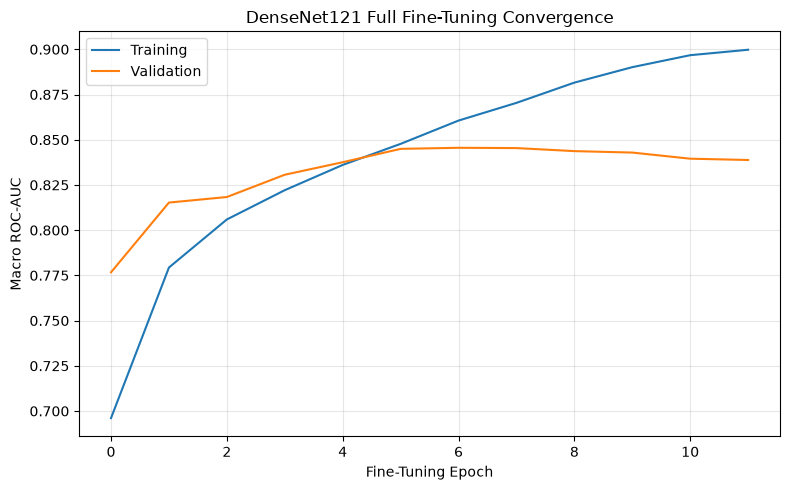

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['auc'], label='Training')
plt.plot(history.history['val_auc'], label='Validation')
plt.xlabel('Fine-Tuning Epoch')
plt.ylabel('Macro ROC-AUC')
plt.title('DenseNet121 Full Fine-Tuning Convergence')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/cnn_training_curve.png', dpi=300, bbox_inches='tight')
plt.show()

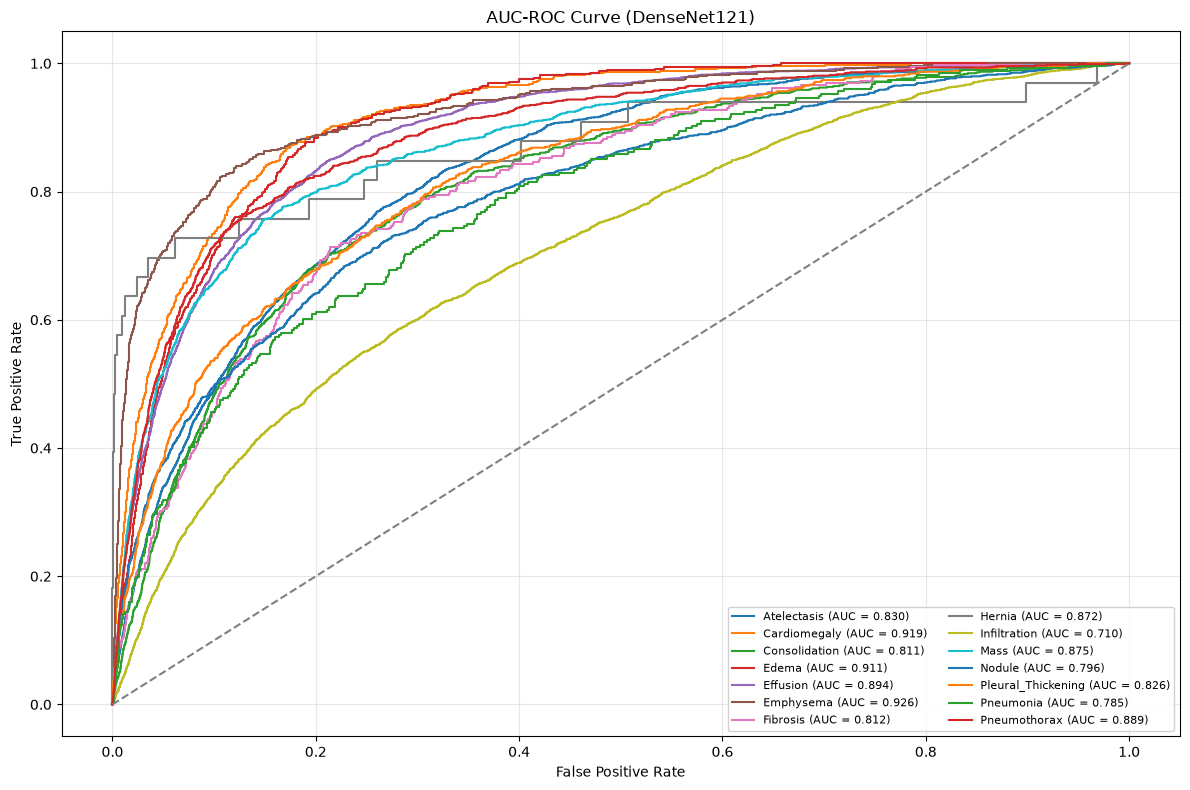

In [20]:
plt.figure(figsize=(12, 8))
for c, name in enumerate(disease_classes):
    fpr, tpr, _ = roc_curve(Y_test[:, c], test_probabilities[:, c])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AUC-ROC Curve (DenseNet121)')
plt.legend(loc='lower right', fontsize=8, ncol=2, framealpha=0.9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/cnn_roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()